In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from io import BytesIO
from pathlib import Path
import os

print("Projeto Burnout - Ecossistema Hadoop")
print("Faça upload do arquivo CSV bruto gerado pelo projeto.")

arquivos = files.upload()

nome_arquivo = next(iter(arquivos))

# Leitura do arquivo CSV
try:
    df = pd.read_csv(BytesIO(arquivos[nome_arquivo]))
except UnicodeDecodeError:
    df = pd.read_csv(
        BytesIO(arquivos[nome_arquivo]),
        encoding="latin-1"
    )

print("\nArquivo carregado:", nome_arquivo)
print("Quantidade de registros:", len(df))
print("Quantidade de colunas:", len(df.columns))

display(df.head())

Projeto Burnout - Ecossistema Hadoop
Faça upload do arquivo CSV bruto gerado pelo projeto.


Saving burnout_bruto.csv to burnout_bruto (1).csv

Arquivo carregado: burnout_bruto (1).csv
Quantidade de registros: 1020
Quantidade de colunas: 8


,id_colaborador,nome,departamento,horas_extras,horas_trabalhadas,tickets_fora_horario,horario_ticket,nivel_clima
0,1523,Srta. Isabella Sousa,Recursos Humanos,3.2,8.7,6,16:08,9.0
1,1602,Lucas Gabriel Machado,Recursos Humanos,12.5,7.7,1,11:01,3.0
2,1526,Bernardo Vasconcelos,TI,19.4,11.0,3,08h24,1.0
3,1031,Stephany Lopes,Tecnologia da Informação,15.7,10.3,1,19:12,9.0
4,1616,Theodoro da Cruz,Comercial,15.6,10.2,4,16:40,8.0


In [ ]:
# Visualização das colunas existentes
print("COLUNAS DISPONÍVEIS:")
print(df.columns.tolist())

print("\nDIMENSÕES DA BASE:")
print(df.shape)

print("\nTIPOS DE DADOS:")
print(df.dtypes)

print("\nVALORES AUSENTES:")
print(df.isnull().sum())

print("\nESTATÍSTICAS DESCRITIVAS:")
display(df.describe(include="all").T)

COLUNAS DISPONÍVEIS:
['id_colaborador', 'nome', 'departamento', 'horas_extras', 'horas_trabalhadas', 'tickets_fora_horario', 'horario_ticket', 'nivel_clima']

DIMENSÕES DA BASE:
(1020, 8)

TIPOS DE DADOS:
id_colaborador            int64
nome                     object
departamento             object
horas_extras            float64
horas_trabalhadas       float64
tickets_fora_horario      int64
horario_ticket           object
nivel_clima             float64
dtype: object

VALORES AUSENTES:
id_colaborador           0
nome                     0
departamento             0
horas_extras            50
horas_trabalhadas        0
tickets_fora_horario     0
horario_ticket          30
nivel_clima             51
dtype: int64

ESTATÍSTICAS DESCRITIVAS:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_colaborador,1020.0,NaN,NaN,NaN,1501.918627,288.735731,1000.0,1252.75,1504.5,1751.25,1999.0
nome,1020,987,Luiz Otávio Pimenta,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departamento,1020,9,Tecnologia da Informação,124,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horas_extras,970.0,NaN,NaN,NaN,11.983711,5.696721,0.0,7.725,11.95,15.875,28.4
horas_trabalhadas,1020.0,NaN,NaN,NaN,8.536275,1.51949,4.2,7.5,8.5,9.5,13.2
tickets_fora_horario,1020.0,NaN,NaN,NaN,2.927451,1.680177,0.0,2.0,3.0,4.0,9.0
horario_ticket,990,828,16:41,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_clima,969.0,NaN,NaN,NaN,5.435501,2.865118,1.0,3.0,5.0,8.0,10.0


In [ ]:
# SIMULAÇÃO DO HDFS

os.makedirs("/content/hdfs_simulado/bronze", exist_ok=True)
os.makedirs("/content/hdfs_simulado/silver", exist_ok=True)
os.makedirs("/content/hdfs_simulado/gold", exist_ok=True)

# Salvar os dados brutos na camada Bronze
caminho_bronze = "/content/hdfs_simulado/bronze/dados_burnout.csv"
df.to_csv(caminho_bronze, index=False)

print("Simulação do HDFS concluída.")
print("Camada Bronze:", caminho_bronze)
print("Registros armazenados:", len(df))

print("\nEstrutura simulada:")
print("HDFS/")
print(" ├── bronze/  -> dados brutos")
print(" ├── silver/  -> dados tratados")
print(" └── gold/    -> dados consolidados")

Simulação do HDFS concluída.
Camada Bronze: /content/hdfs_simulado/bronze/dados_burnout.csv
Registros armazenados: 1020

Estrutura simulada:
HDFS/
 ├── bronze/  -> dados brutos
 ├── silver/  -> dados tratados
 └── gold/    -> dados consolidados


In [ ]:
# ============================================================
# TRATAMENTO DOS DADOS - CAMADA SILVER
# ============================================================

df_silver = df.copy()

# Remover registros completamente duplicados
duplicados_antes = df_silver.duplicated().sum()
df_silver = df_silver.drop_duplicates()

# Identificar colunas numéricas e textuais
colunas_numericas = df_silver.select_dtypes(
    include=np.number
).columns.tolist()

colunas_texto = df_silver.select_dtypes(
    include=["object", "string"]
).columns.tolist()

# Preencher valores numéricos ausentes com a mediana
for coluna in colunas_numericas:
    if df_silver[coluna].notna().any():
        df_silver[coluna] = df_silver[coluna].fillna(
            df_silver[coluna].median()
        )

# Preencher textos ausentes com "Não informado"
for coluna in colunas_texto:
    df_silver[coluna] = (
        df_silver[coluna]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Não informado")
    )

# Salvar os dados tratados
caminho_silver = "/content/hdfs_simulado/silver/dados_burnout_tratados.csv"
df_silver.to_csv(caminho_silver, index=False)

print("Tratamento concluído.")
print("Duplicatas removidas:", duplicados_antes)
print("Registros após tratamento:", len(df_silver))

print("\nValores ausentes restantes:")
print(df_silver.isnull().sum())

display(df_silver.head())

Tratamento concluído.
Duplicatas removidas: 19
Registros após tratamento: 1001

Valores ausentes restantes:
id_colaborador          0
nome                    0
departamento            0
horas_extras            0
horas_trabalhadas       0
tickets_fora_horario    0
horario_ticket          0
nivel_clima             0
dtype: int64


,id_colaborador,nome,departamento,horas_extras,horas_trabalhadas,tickets_fora_horario,horario_ticket,nivel_clima
0,1523,Srta. Isabella Sousa,Recursos Humanos,3.2,8.7,6,16:08,9.0
1,1602,Lucas Gabriel Machado,Recursos Humanos,12.5,7.7,1,11:01,3.0
2,1526,Bernardo Vasconcelos,TI,19.4,11.0,3,08h24,1.0
3,1031,Stephany Lopes,Tecnologia da Informação,15.7,10.3,1,19:12,9.0
4,1616,Theodoro da Cruz,Comercial,15.6,10.2,4,16:40,8.0


In [ ]:
# ============================================================
# SIMULAÇÃO DO MAPREDUCE
# ============================================================

# Procurar uma coluna que represente departamento ou setor
coluna_grupo = next(
    (
        coluna for coluna in df_silver.columns
        if any(
            termo in coluna.lower()
            for termo in ["departamento", "setor", "area", "área"]
        )
    ),
    None
)

if coluna_grupo is not None:
    # MAP: associar cada registro à sua categoria
    dados_map = df_silver[
        [coluna_grupo] + colunas_numericas
    ].copy()

    print("MAP: registros associados à coluna:", coluna_grupo)
    display(dados_map.head())

    # REDUCE: agrupar e calcular médias
    if colunas_numericas:
        resultado_reduce = (
            dados_map
            .groupby(coluna_grupo)[colunas_numericas]
            .mean()
            .reset_index()
        )

        print("\nREDUCE: médias numéricas por grupo")
        display(resultado_reduce)

        resultado_reduce.to_csv(
            "/content/hdfs_simulado/gold/resumo_por_departamento.csv",
            index=False
        )
    else:
        print("Não existem colunas numéricas para agregar.")
else:
    print(
        "Não foi encontrada uma coluna de departamento ou setor."
    )
    print("Resumo numérico geral da base:")

    if colunas_numericas:
        resultado_reduce = df_silver[colunas_numericas].mean().to_frame(
            name="media"
        )
        display(resultado_reduce)
    else:
        resultado_reduce = pd.DataFrame()
        print("A base não possui colunas numéricas.")

MAP: registros associados à coluna: departamento


,departamento,id_colaborador,horas_extras,horas_trabalhadas,tickets_fora_horario,nivel_clima
0,Recursos Humanos,1523,3.2,8.7,6,9.0
1,Recursos Humanos,1602,12.5,7.7,1,3.0
2,TI,1526,19.4,11.0,3,1.0
3,Tecnologia da Informação,1031,15.7,10.3,1,9.0
4,Comercial,1616,15.6,10.2,4,8.0



REDUCE: médias numéricas por grupo


,departamento,id_colaborador,horas_extras,horas_trabalhadas,tickets_fora_horario,nivel_clima
0,Comercial,1453.530435,11.651304,8.536522,2.895652,5.234783
1,Financeiro,1495.330579,11.953719,8.339669,2.570248,5.586777
2,Operacoes,1434.645455,12.772727,8.720909,2.809091,5.445455
3,Operações,1469.058824,11.821569,8.652941,3.009804,5.205882
4,RH,1526.131579,11.495614,8.414035,2.991228,5.043860
5,Recursos Humanos,1526.641509,11.781132,8.716981,3.066038,5.679245
6,TI,1517.945055,11.948352,8.416484,2.901099,5.692308
7,Tecnologia da Informação,1542.857143,12.228571,8.583193,3.151261,5.344538
8,ti,1528.113821,11.873171,8.449593,2.943089,5.788618


In [ ]:
# ============================================================
# SIMULAÇÃO DO YARN
# ============================================================

total_registros = len(df_silver)
total_colunas = len(df_silver.columns)
total_numericas = len(colunas_numericas)

trabalho_yarn = pd.DataFrame([{
    "trabalho": "Analise_Burnout_MapReduce",
    "status": "Concluído",
    "registros_processados": total_registros,
    "total_colunas": total_colunas,
    "colunas_numericas": total_numericas,
    "ambiente": "Simulação em Python"
}])

print("Relatório de execução - YARN simulado")
display(trabalho_yarn)

trabalho_yarn.to_csv(
    "/content/hdfs_simulado/gold/relatorio_execucao.csv",
    index=False
)

Relatório de execução - YARN simulado


,trabalho,status,registros_processados,total_colunas,colunas_numericas,ambiente
0,Analise_Burnout_MapReduce,Concluído,1001,8,5,Simulação em Python


In [ ]:
# ============================================================
# SIMULAÇÃO DO APACHE HIVE
# ============================================================

print("Consulta semelhante ao Hive: quantidade de registros")

consulta_total = pd.DataFrame({
    "total_registros": [len(df_silver)],
    "total_colunas": [len(df_silver.columns)]
})

display(consulta_total)

if coluna_grupo is not None:
    print("\nConsulta semelhante ao Hive: registros por departamento")

    consulta_grupos = (
        df_silver
        .groupby(coluna_grupo)
        .size()
        .reset_index(name="quantidade_registros")
        .sort_values("quantidade_registros", ascending=False)
    )

    display(consulta_grupos)
else:
    print(
        "Para consultar por departamento no Hive, "
        "a base precisa conter uma coluna de departamento ou setor."
    )

Consulta semelhante ao Hive: quantidade de registros


,total_registros,total_colunas
0,1001,8



Consulta semelhante ao Hive: registros por departamento


,departamento,quantidade_registros
8,ti,123
1,Financeiro,121
7,Tecnologia da Informação,119
0,Comercial,115
4,RH,114
2,Operacoes,110
5,Recursos Humanos,106
3,Operações,102
6,TI,91


In [ ]:
# ============================================================
# ANÁLISE DOS INDICADORES DO PROJETO BURNOUT
# ============================================================

termos_indicadores = [
    "horas_extras",
    "horas extras",
    "horas_trabalhadas",
    "horas trabalhadas",
    "tickets_fora_horario",
    "tickets fora do horario",
    "risco_burnout",
    "risco burnout",
    "clima"
]

colunas_indicadores = [
    coluna for coluna in df_silver.columns
    if any(
        termo in coluna.lower()
        for termo in termos_indicadores
    )
]

print("Indicadores encontrados:")
print(colunas_indicadores)

if colunas_indicadores:
    display(df_silver[colunas_indicadores].head(10))
else:
    print(
        "Nenhuma coluna com esses nomes foi identificada. "
        "Confira os nomes exibidos na segunda célula."
    )

Indicadores encontrados:
['horas_extras', 'horas_trabalhadas', 'tickets_fora_horario', 'nivel_clima']


,horas_extras,horas_trabalhadas,tickets_fora_horario,nivel_clima
0,3.2,8.7,6,9.0
1,12.5,7.7,1,3.0
2,19.4,11.0,3,1.0
3,15.7,10.3,1,9.0
4,15.6,10.2,4,8.0
5,13.1,9.2,1,5.0
6,7.0,9.3,3,7.0
7,3.5,7.7,3,2.0
8,4.1,11.2,2,8.0
9,17.9,6.5,2,5.0


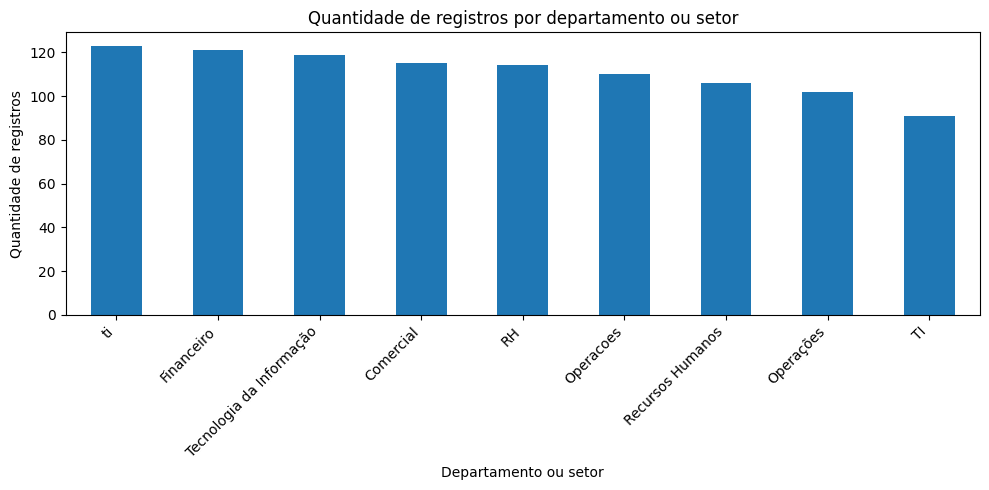

In [ ]:
# ============================================================
# VISUALIZAÇÃO DOS DADOS
# ============================================================

if coluna_grupo is not None:
    contagem = df_silver[coluna_grupo].value_counts().head(10)

    plt.figure(figsize=(10, 5))
    contagem.plot(kind="bar")
    plt.title("Quantidade de registros por departamento ou setor")
    plt.xlabel("Departamento ou setor")
    plt.ylabel("Quantidade de registros")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

elif colunas_numericas:
    medias = df_silver[colunas_numericas].mean().head(10)

    plt.figure(figsize=(10, 5))
    medias.plot(kind="bar")
    plt.title("Média das variáveis numéricas da base")
    plt.xlabel("Variáveis")
    plt.ylabel("Média")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

else:
    print("Não há dados adequados para criar o gráfico.")

In [ ]:
# ============================================================
# EXPORTAÇÃO DOS RESULTADOS
# ============================================================

import shutil

pasta_resultados = "/content/resultados_hadoop_burnout"

if os.path.exists(pasta_resultados):
    shutil.rmtree(pasta_resultados)

shutil.copytree(
    "/content/hdfs_simulado",
    pasta_resultados
)

arquivo_zip = shutil.make_archive(
    "/content/resultados_hadoop_burnout",
    "zip",
    pasta_resultados
)

print("Processamento finalizado!")
print("Arquivo de resultados:", arquivo_zip)

files.download(arquivo_zip)

Processamento finalizado!
Arquivo de resultados: /content/resultados_hadoop_burnout.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>